# Student Mission Control Expedition 1: Altitude

## Introduction

### Running Code in Jupyter Notebooks

The goal of these expeditions is to teach you about data science as well as what it's like to operate the Interntional Space Station. Specifically, we'll look at real unfiltered data from the International Space Station to gain a deeper understanding of how the ISS works and what it's like to live aboard. Instead of having to rely on youtube videos or wikipedia articles, we'll be able to look at the data ourselves and try to understand the story hidden inside the data.




Let's see how notebooks can run code that will help us understand data science.

In the next cell, click inside the code box and press Shift + Enter (or click the ▶ Run button in the toolbar). The code will run and generate a visualization using real penguin data.

Each dot on this plot is a different penguin. We see that Gentoo penguins tend to be heavier than the other two species of penguins, and that Adelie Penguins tend to have the shortest billed beaks. This is just a silly example, of course, and has nothing to do with the space station.

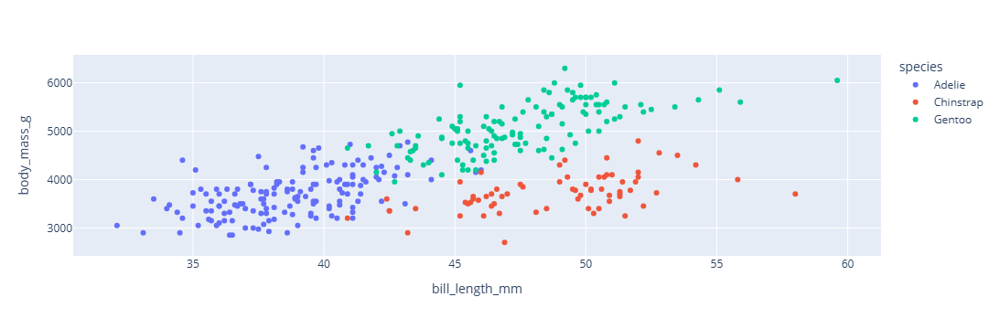

In [1]:
import seaborn as sns
import plotly.express as px
penguins = sns.load_dataset("penguins")
px.scatter(penguins, x = "bill_length_mm", y = "body_mass_g", color = "species")

## Introduction to International Space Station Data

There are no penguins in space of course (that we know of). Instead, the data we'll be exploring in this lab all comes from the International Space Station, with a population of five to seven people flying over the Earth at over 17,000 miles per hour.

The International Space Station is continuously collecting data and relaying it back to earth. This data comes in many forms. Some of this data is the output of the many scientific experiments being run on the station. Some of this data are videos created by crew members, such as [this tour by Sunita Williams](https://www.youtube.com/watch?v=doN4t5NKW-k) or [this video of Chris Hadfield making a tasty snack](https://www.youtube.com/watch?v=AZx0RIV0wss).

Throughout these three labs, we’ll focus on a different type of data, specifically the data related to the daily operations of the space station, e.g. the temperature onboard, the location of the ISS, and how full the urine tanks are (seriously).

This data is important! Sensors track the altitude of the space station, and when it gets too low, the space station boosts itself back up using thrusters to a higher orbit. When a leak is sprung, crew members and ground crews are alerted in real time before things get dangerous.

### TASK 1: Manually Looking at Data

It's time to do something. Let's take a look at the real live data being sent by the International Space Station.


* Go to https://iss-mimic.github.io/Mimic/.
* On that page, search (using your web browser) for the text "Altitude from State Vectors".
* Take note of the value. That's the current altitude of the space station in kilometers.
* If no value is displayed, make note of that the telemetry feed is currently unavailable and continue to the next activity


On that line of the page, you'll see the actual current height of the space station above the Earth in kilometers. You'll see it is many hundreds of kilometers above the surface of the Earth. The only reason the ISS is able to stay in orbit is because the air is very thin at that altitude. If it were too low, collisions with air molecules would cause it to slow down rapidly, eventually causing it to crash into the thick atmosphere below. Since the space station is moving at nearly 20,000 miles per hour, the space station would be totally destroyed if it were to go too low. So obviously keeping track of the altitude is pretty important!

Fun fact: Space is traditionally defined as 100 kilometers above the surface of the Earth (or 62 miles). This is the so-called [Kármán line](https://en.wikipedia.org/wiki/K%C3%A1rm%C3%A1n_line).

Fun fact about the fun fact: Theodore von Karman, for whom the Karman line is named, was originally named Theodore von **Skőllőskislaki** Kármán. As Theodore himself stated: "To receive a predicate of nobility, my father had to be landed. Fortunately he owned a small vineyard near Budapest, so the Emperor bestowed upon him the predicate "von **Skőllőskislaki**" (small grape). I have shortened it to von, for even to me, a Hungarian, the full title is almost unpronounceable".

### Acquiring Historical Data

https://iss-mimic.github.io/Mimic/ only shows the data that is coming from the Space Station right now. We want to look back at older data spanning weeks and months to try to learn about what goes into operating and living on board the Space Station.

Run the cell below (starting with `!git clone ...`). Note you can do this either by pressing the play button as before, or if you want you can press Shift + Enter.

You should see something that looks like:

```
Cloning into 'smcLab'...
...
Unpacking objects: 100% (14/14), done.
```

In [2]:
!git clone https://github.com/joshhug/smcLab.git
!rm -rf smclib
!rm -rf data
!mv smcLab/smclib ./
!mv smcLab/data ./
!rm -rf smcLab

Cloning into 'smcLab'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 39 (delta 7), reused 31 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 16.33 MiB | 22.66 MiB/s, done.
Resolving deltas: 100% (7/7), done.
Updating files: 100% (10/10), done.


That code above downloaded all the data and code files that I created (oh btw, I'm [Josh Hug](https://www2.eecs.berkeley.edu/Faculty/Homepages/joshhug.html), a CS professor at Berkeley. Feel free to send feedback to your teacher to pass on to me if you have any particular questions or comments.)

Now run the cell below. This "imports" some libraries. Don't worry about what this means. You'll see a message that says "Libraries imported!"

In [3]:
import pandas as pd
import plotly.express as px
import re
import seaborn as sns
from smclib.utils import read_iss_data
from smclib.utils import plot_ypr
from smclib.utils import box_plot, line_plot, histogram, hourly_average
print("Libraries imported!")

Libraries imported!


**Quick Note:** In case the notebook or kernel freezes, times out, or dies, you may restart the kernel in Kernel -> Restart Kernel.

**Quick Note:** If you are idle for too long, your kernel will automatically terminate. You'll need to re-run all of the cells again.

## Analyzing Altitude: Univariate Case

Let's start doing some data analysis using the "pandas" library. You don't have to know how it works or how to write code that uses pandas, you just have to run the code we provided.

Run the cell below, which will read in some historical altitude data that spans 50 days from November 12th, 2019 to December 31st, 2019.

When you run this cell, you won't see anything printed. However, you should see a number appear in the brackets next to the cell.

In [4]:
alt = read_iss_data('data/altitude.csv')

### A Manual Look at Historical Data

Run the cell below, which will show the first and last 5 rows of data in the historical record we've provided.

You'll see that November 12th, 2019, the altitude was 417.88 kilometers and by the end of December, it was almost 421 kilometers.

We see that there are a toital of 171,243 observations over those 50 days, and each observation has exactly two properties, the time and altitude.

In [5]:
alt

,dtime,altitude
0,2019-11-12 00:00:04.602999926,417.877699
1,2019-11-12 00:00:14.602999926,417.860661
2,2019-11-12 00:00:24.602999926,417.843065
3,2019-11-12 00:00:34.602999926,417.824915
4,2019-11-12 00:00:44.602999926,417.806204
...,...,...
171238,2019-12-31 23:59:14.602999926,420.526766
171239,2019-12-31 23:59:24.602999926,420.625551
171240,2019-12-31 23:59:34.602999926,420.723496
171241,2019-12-31 23:59:44.602999926,420.820479


Now run the cell below, which will provide a summary of the provided historical data over the entire 50 day period.

The summary includes:
- number of valid (non-null) data points (`count`)
- average (`mean`)
- standard deviation (`std`)
- minimum value (`min`)
- maximum value (`max`)
- 25th percentile (or 1st quartile, `25%`)
- median (`50%`)
- 75th percentile (or 3rd quartile, `75%`)

Some or all of these ideas may be familiar to you from statistics.

If you're not familiar with standard deviation, you might find this [youtube video](https://www.youtube.com/watch?v=MRqtXL2WX2M) helpful.

In [6]:
alt.describe()

,dtime,altitude
count,171243,171243.000000
mean,2019-12-08 10:26:40.082633984,417.435709
min,2019-11-12 00:00:04.602999926,406.169486
25%,2019-11-26 12:39:19.602999808,413.021556
50%,2019-12-09 07:24:24.602999808,416.825616
75%,2019-12-20 16:53:28.698999808,423.231074
max,2019-12-31 23:59:54.602999926,426.280676
std,NaN,5.600021


## TASK 2: Understanding the Data

As noted earlier, to ensure that the ISS is stable in its orbit, it is crucial that it maintains a reasonable altitude. Even at its altitude of 400 km, there is still a very thin atmopshere. And the lower you go, the thicker it gets. As an example, if the space station were to reach 200 km, its orbit would rapidly decay, resulting in its destruction in less than a day. Hitting the atmosphere at 17,000 miles per hour is no joke.

From the data displayed above above, answer the following questions:

- On average, how many observations (rows) seem to be recorded per minute and per hour?
- What is the absolute lowest altitude in kilometers that the ISS reached over that time?
- Roughly how much did the altitude in kilometers of the space station vary over this time period?

Everything you need to know to answers these questions is somewhere in the output of the code run above.

## TASK 3: Interpreting the Data

It may surprise you that the space station's altitude  varies.

It's also interesting (to me at least) to ask: Why these specific altitudes? Why not 300 km? Why not 600 km? Why is the standard deviation 5.6 kilometers and not 50?

Before we proceed, talk to your fellow students and formulate a hypothesis for the following question:

**Why does the ISS's altitude vary? That is, why does the ISS go up and down?**

If you don't have a good answer, that's fine, come up with some ideas and we'll talk about the answer later.

## TASK 4: Statistical Visualization of the Data

## Creating a Box Plot

We can visualize these statistics using a **boxplot**, which simply shows the statistics shown above. An example is given below. We'll use box plots again in a later Expedition.

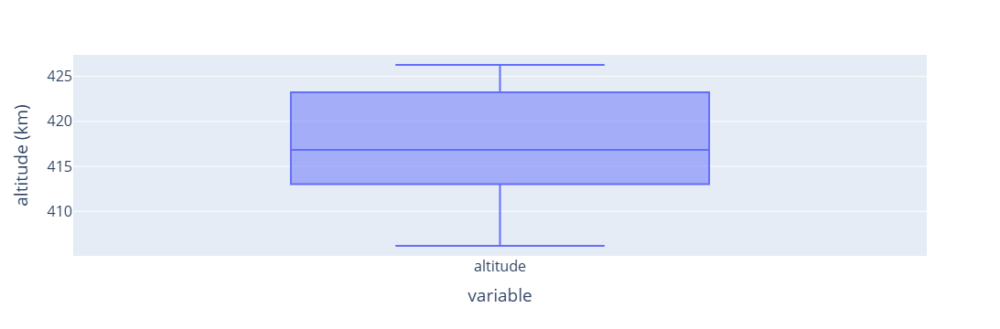

In [7]:
box_plot(alt, "altitude")

Another type of visualization is a **histogram**, showing how frequently each altitude occurred over the time period. Run the cell below. Note that the graph that appears is not a plot vs. time, but rather a plot of how often the space station was at each altitude.

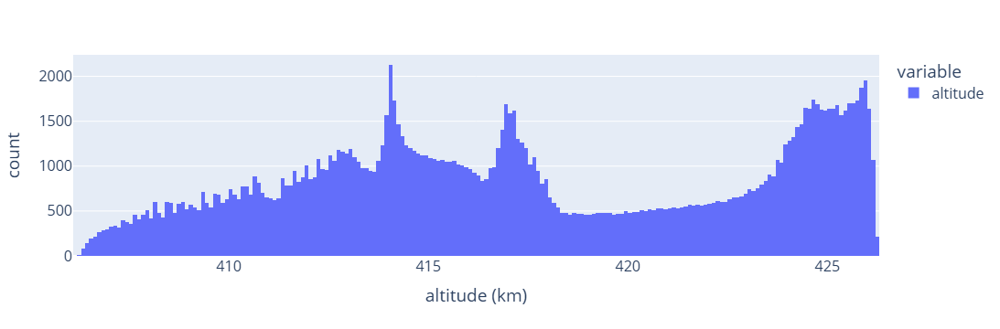

In [8]:
histogram(alt, "altitude")

Question:
 * What altitude was the most common (tip: you can hover your cursor over the plot)?

Note that the histogram doesn't tell us anything about WHEN the observations happened. That is, we don't know how the altitude changed over time, just which altitudes were relatively common.


## TASK 5: Estimating the Orbit Time Using the Line Plot

### Visualizing Altitude Over Time

A much more natural visualization is a simple plot of altitude over time, also known as a **line plot**.

Run the cell below, and you'll see the line plot of altitude over time.

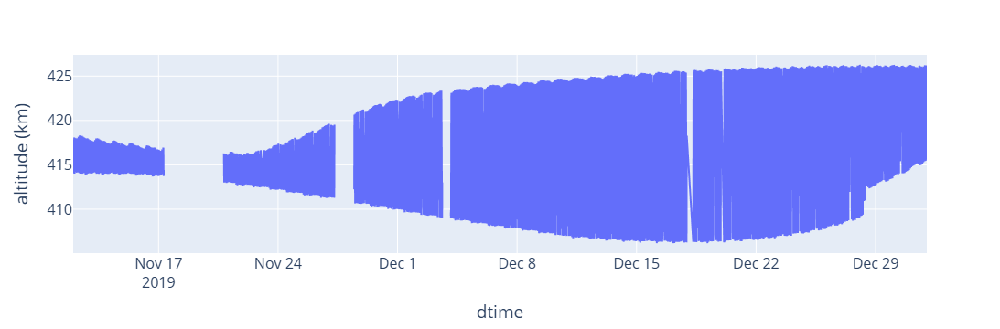

In [9]:
line_plot(alt, x = "dtime", y = "altitude")

What a funny shape! There's a lot to think about and explore here.

Our plot supports the ability to zoom. Click the Zoom tool (it's actually selected by default), then click and drag your mouse over a window of the data, and you'll see a zoomed in view.

To zoom back out, either click the minus button to zoom out a little bit, or the home logo (hover over the top right of the image and you'll see the house appaer) to zoom all the way out.

Note: The camera logo (leftmost) downloads the plot as an image and saves it to your computer. We will not use this in the notebook, but you may download and store interesting findings as the plot will not be saved otherwise.

Start by **zooming in on just a few days of data**.

You'll see the altitude looks wiggly, going from high to low to high to low, and so forth. Each one of these wiggles represents an orbit.

Question:
 * Using the data, try to estimate the amount of time it takes for the ISS to complete one orbit around the Earth.

## TASK 6: Estimating the Orbit Time Using Math

As we saw, the orbit of the space station is around **400 kilometers**, and is orbiting at around 17,000 miles per hour, which is around **27,000 kilometers per hour**.

Furthermore the radius of the Earth is around **6400 kilometers**.

Using these three numbers, estimate the time per orbit and compare to your answer from before.

Hint: Each orbit is basically a circle around the Earth.

Hint 2: The circumference of a circle is $2\pi r$.

## TASK 7: Interpreting Each Orbit

Here's a fun but tricky question. Suppose the orbit of the ISS around the earth was a **perfect circle**.

In this case, why would it be hard to estimate the orbit time using the line plot?

Hint: What would the line plot look like?

## Elliptical Orbits

As you might have surmised, the reason the space station's altitude varies during each orbit is that its orbit is slightly elliptical, i.e. shaped like an oval. If its orbit were exactly circular, it's altitude would not change at all as it orbited the earth.

The degree to which an orbit is circular is known as its "[eccentricity](https://en.wikipedia.org/wiki/Orbital_eccentricity)." An eccentricity of 0 means it is a perfect circle. An eccentricity of between 0 and 1 means it is an ellipse. (And if the eccentricity exceeds 1, it's a hyperbola, meaning given infinite time, it would fly infinitely far away). The animation below from Wikipedia user Phoenix7777 shows orbits of various eccentricity, with the red orbit being perfectly circular (0.0) and the pink orbit being highly eccentric (0.8).

![Diagram of Eccentricity.](https://upload.wikimedia.org/wikipedia/commons/f/fa/Animation_of_Orbital_eccentricity.gif)


For a real example of a highly elliptical orbit, see this [video of the Solar Parker Probe](https://www.youtube.com/watch?v=cMNQeCWT09A).

The Parker Solar Probe dives deep close to the sun, experiencing sunlight that is almost 500 times as bright as it is at the distance of Earth, before flying way back out to the orbit of Venus. It only spends a brief time close to the sun, since it's moving so fast at the "bottom" of its orbit, and spends most of its time moving slowly at the "top" of its orbit.

The lowest point in an orbit is called the periapsis, and the highest point is the apoapsis. For more see [https://en.wikipedia.org/wiki/Apsis](https://en.wikipedia.org/wiki/Apsis). For example, the periapsis of the Parker Solar Probe is around 7 million kilometers from the sun, and the apoapsis is around 100 kilometers from the sun. This is a highly elliptical orbit!

Note that for orbits around the earth, the periapsis is usually called the perigee and the apoapsis is usually called the apogee.

## Task 8: Intepreting the Eccentricity of the ISS's Orbit

Go back to the line plot from earlier and answer the following questions:

 - What were the approximate perigee and apogee of the orbits for the Space Station on December 15, 2019?
 - Give an example of a date when the ISS's orbit was especially circular. Give an example of a date when the ISS's orbit was relatively elliptical.

## Task 9: Understanding the Sudden Increase in Late December

Let's look at the line plot of the ISS orbit again.


In [ ]:
line_plot(alt, x = "dtime", y = "altitude")

Above, we saw that one major reason for variation for the ISS is that the orbit is elliptical.

There are other types of changes we see in the orbit, for example, the long decline in perigee until approximately December 15th. We also see the apogee creeping up from around November 24th to December 15th. Drag from the atmosphere plays a small role here (the space station loses a few kilometers per year). These long changes to perigee and apogee are related to complex orbital dynamics and orbit measurement issues that are well beyond the scope of this notebook. As a bonus, I've included the email I got back when observing this data. Not very satisfying!

What about the sudden change that we see at the end of December?

For that, try googling: "ISS Daily Summary Report – 12/27/2019".

What do you see?

Solicitation from PD: How do we end this expedition on a punchier note?